# Metrics by Division Level — J&J and Strictly

Divergence metrics across the six main division levels, shown **separately** for
each dance format so the two never share a chart:

- **Jack & Jill** charts are **blue**.
- **Strictly** charts are **red**.

Within each format there is one bar chart (mean across all scoresheets in that
category, with error bars giving the 95% confidence interval of the mean,
±1.96·sd/√n) and one box chart (full distributions).
Levels: Newcomer, Novice, Intermediate, Advanced, All-Star, Champions.

In [1]:
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

project_root = Path(".").resolve().parent

df_raw = pd.read_csv(project_root / "data" / "metrics.csv")
print(f"Total rows: {len(df_raw)}")

Total rows: 2552


In [2]:
LEVEL_LABELS = {
    "Newcomer":     "new",
    "Novice":       "nov",
    "Intermediate": "int",
    "Advanced":     "adv",
    "All-Star":     "als",
    "Champions":    "chp",
}
LEVEL_ORDER = list(LEVEL_LABELS.values())  # new → chp

# Each format gets its own cells, in its own colour, so it is always obvious
# which one a chart is showing.
FORMAT_COLORS = {
    "Jack & Jill": "#636EFA",  # blue
    "Strictly":    "#EF553B",  # red
}

METRICS = [
    # higher = more agreement
    ("kendall_w",               "Kendall's W",                     "higher = more agreement"),
    ("mean_pairwise_rho",       "Mean pairwise Spearman ρ",        "higher = more agreement"),
    ("mean_pairwise_tau",       "Mean pairwise Kendall τ",         "higher = more agreement"),
    ("overlap_at_3",            "Mean overlap @ 3",                "higher = more agreement"),
    ("overlap_at_5",            "Mean overlap @ 5",                "higher = more agreement"),
    ("jaccard_at_3",            "Mean Jaccard @ 3",                "higher = more agreement"),
    ("jaccard_at_5",            "Mean Jaccard @ 5",                "higher = more agreement"),
    # ("min_pairwise_tau",        "Min pairwise τ",                  "higher = more agreement"),
    # ("min_pairwise_rho",        "Min pairwise ρ",                  "higher = more agreement"),

    # lower = more agreement
    ("tau_distance",            "Kendall τ distance",              "lower = more agreement"),
    ("footrule_mean",           "Mean Spearman footrule",          "lower = more agreement"),
    ("mean_abs_rank_dev_mean",  "Mean abs rank deviation (mean)",  "lower = more agreement"),
    ("mean_abs_rank_dev_median","Mean abs rank deviation (median)","lower = more agreement"),
    ("sd_rank",                 "SD of ranks",                     "lower = more agreement"),
    # ("sd_pairwise_tau",         "SD of pairwise τ",                "lower = more consistent"),
    # ("sd_pairwise_rho",         "SD of pairwise ρ",                "lower = more consistent"),
]
metric_cols = [col for col, _, _ in METRICS]

# Shared subplot geometry / titles, reused by both formats' charts.
NCOLS = 4
NROWS = (len(METRICS) + NCOLS - 1) // NCOLS  # 3
subplot_titles = [f"{title}<br><sup>{note}</sup>" for _, title, note in METRICS]
subplot_titles += [""] * (NROWS * NCOLS - len(METRICS))


def level_frame(fmt):
    """Scoresheets for one dance format, with the six-level label column added."""
    sub = df_raw[
        (df_raw["dance_format"] == fmt) &
        (df_raw["division_level"].isin(LEVEL_LABELS))
    ].copy()
    sub["level"] = sub["division_level"].map(LEVEL_LABELS)
    return sub


def bar_fig(fmt):
    """Mean ± 95% CI bar chart for one format, coloured by FORMAT_COLORS[fmt].

    The per-level sample size n is printed in white at the base of each bar, just
    above the x-axis.
    """
    d = level_frame(fmt)
    mean = d.groupby("level")[metric_cols].mean().reindex(LEVEL_ORDER)
    # 95% CI half-width of the mean = 1.96 · sem (sd/√n).
    ci = d.groupby("level")[metric_cols].sem().reindex(LEVEL_ORDER) * 1.96
    counts = d["level"].value_counts().reindex(LEVEL_ORDER).fillna(0).astype(int)
    count_labels = [f"n={n}" for n in counts]

    fig = make_subplots(
        rows=NROWS, cols=NCOLS, subplot_titles=subplot_titles,
        vertical_spacing=0.10, horizontal_spacing=0.06,
    )
    for i, (col, _, _) in enumerate(METRICS):
        row, col_num = divmod(i, NCOLS)
        fig.add_trace(
            go.Bar(
                x=LEVEL_ORDER,
                y=mean[col],
                showlegend=False,
                marker_color=FORMAT_COLORS[fmt],
                text=count_labels,
                textposition="inside",
                insidetextanchor="start",   # pin labels to the base of each bar
                textangle=0,
                textfont=dict(color="white", size=9),
                cliponaxis=False,
                error_y=dict(type="data", array=ci[col], visible=True,
                             thickness=1.2, color="#444"),
            ),
            row=row + 1, col=col_num + 1,
        )
    fig.update_layout(
        height=NROWS * 350,
        title=f"{fmt} — divergence metrics by division level (mean ± 95% CI; n at bar base)",
    )
    return fig


def box_fig(fmt):
    """Distribution (box) chart for one format, coloured by FORMAT_COLORS[fmt]."""
    d = level_frame(fmt)
    fig = make_subplots(
        rows=NROWS, cols=NCOLS, subplot_titles=subplot_titles,
        vertical_spacing=0.10, horizontal_spacing=0.06,
    )
    for i, (col, _, _) in enumerate(METRICS):
        row, col_num = divmod(i, NCOLS)
        fig.add_trace(
            go.Box(
                x=d["level"], y=d[col],
                showlegend=False, marker_color=FORMAT_COLORS[fmt],
            ),
            row=row + 1, col=col_num + 1,
        )
    fig.update_layout(
        height=NROWS * 350,
        title=f"{fmt} — divergence metrics by division level (distributions)",
    )
    fig.update_xaxes(categoryorder="array", categoryarray=LEVEL_ORDER)
    return fig


# Scoresheet counts per format and level (sanity check before plotting).
for fmt in FORMAT_COLORS:
    d = level_frame(fmt)
    print(f"{fmt}: {len(d)} rows")
    print(d["level"].value_counts().reindex(LEVEL_ORDER).to_string(), "\n")

Jack & Jill: 1234 rows
level
new    218
nov    255
int    250
adv    225
als    209
chp     77 

Strictly: 439 rows
level
new      8
nov    130
int    137
adv     65
als     43
chp     56 



## Jack & Jill <span style="color:#636EFA">(blue)</span>

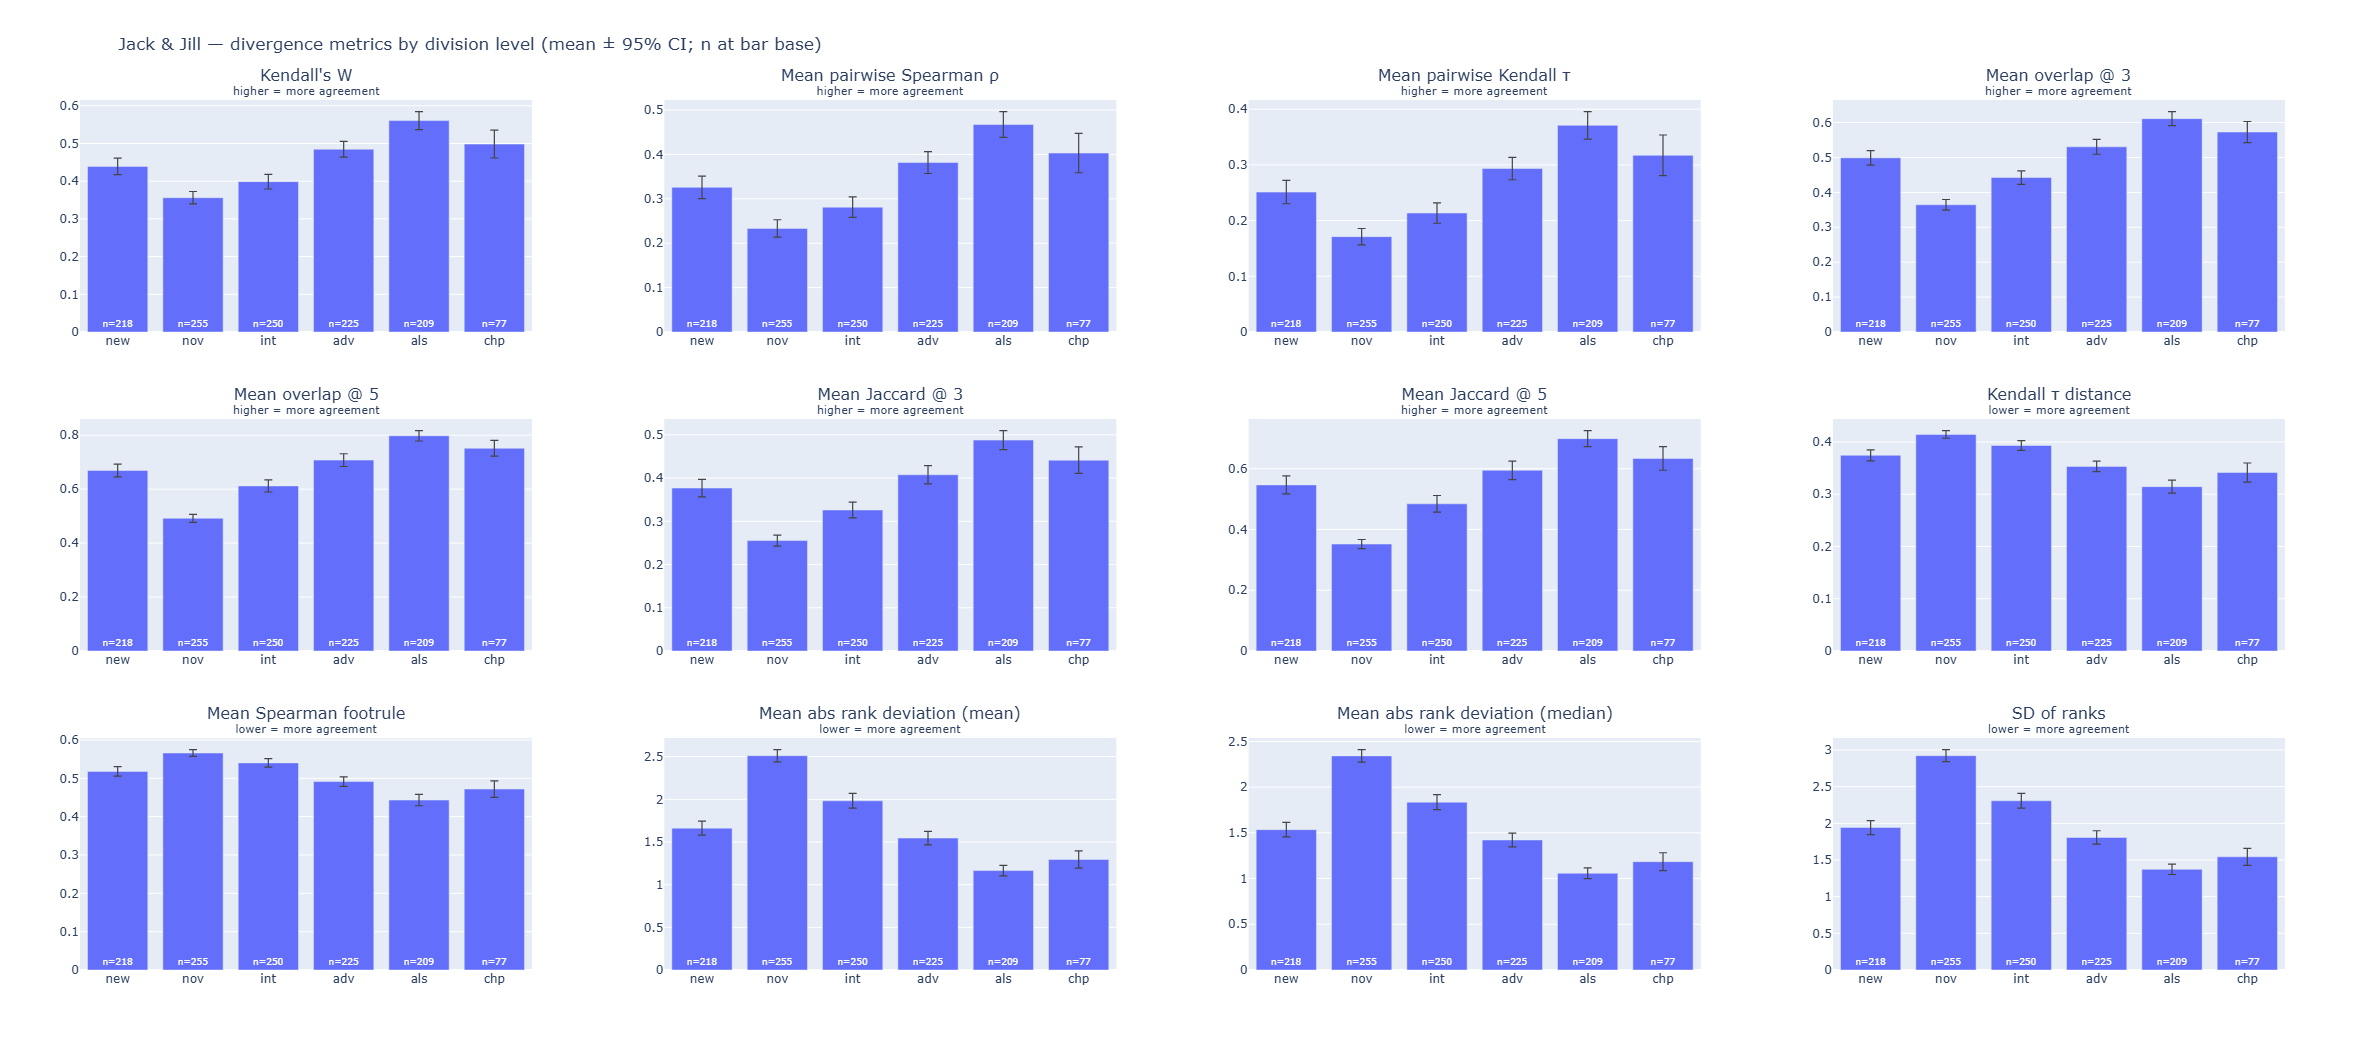

In [3]:
bar_fig("Jack & Jill").show()

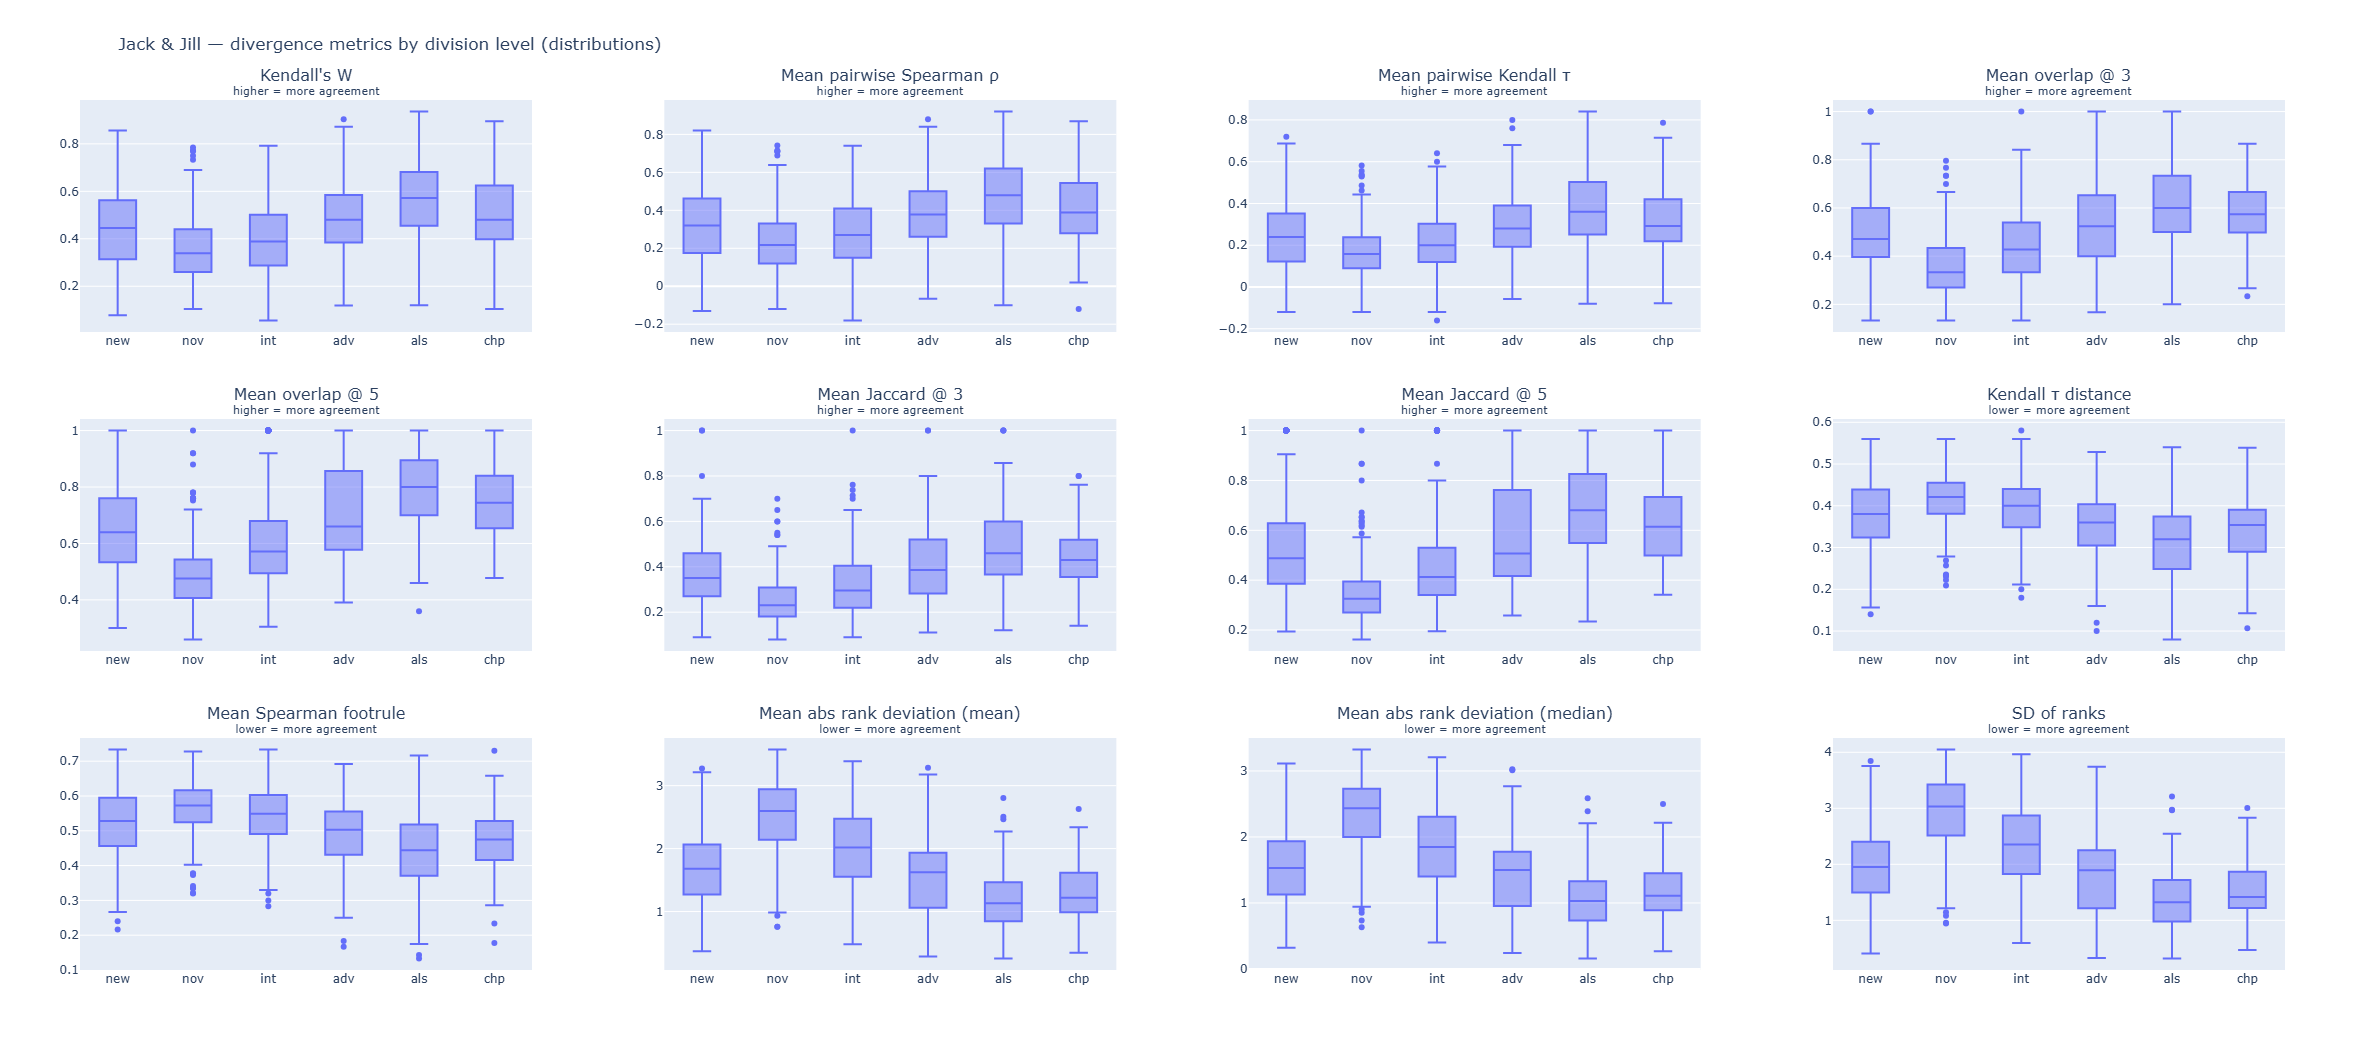

In [4]:
box_fig("Jack & Jill").show()

## Strictly <span style="color:#EF553B">(red)</span>

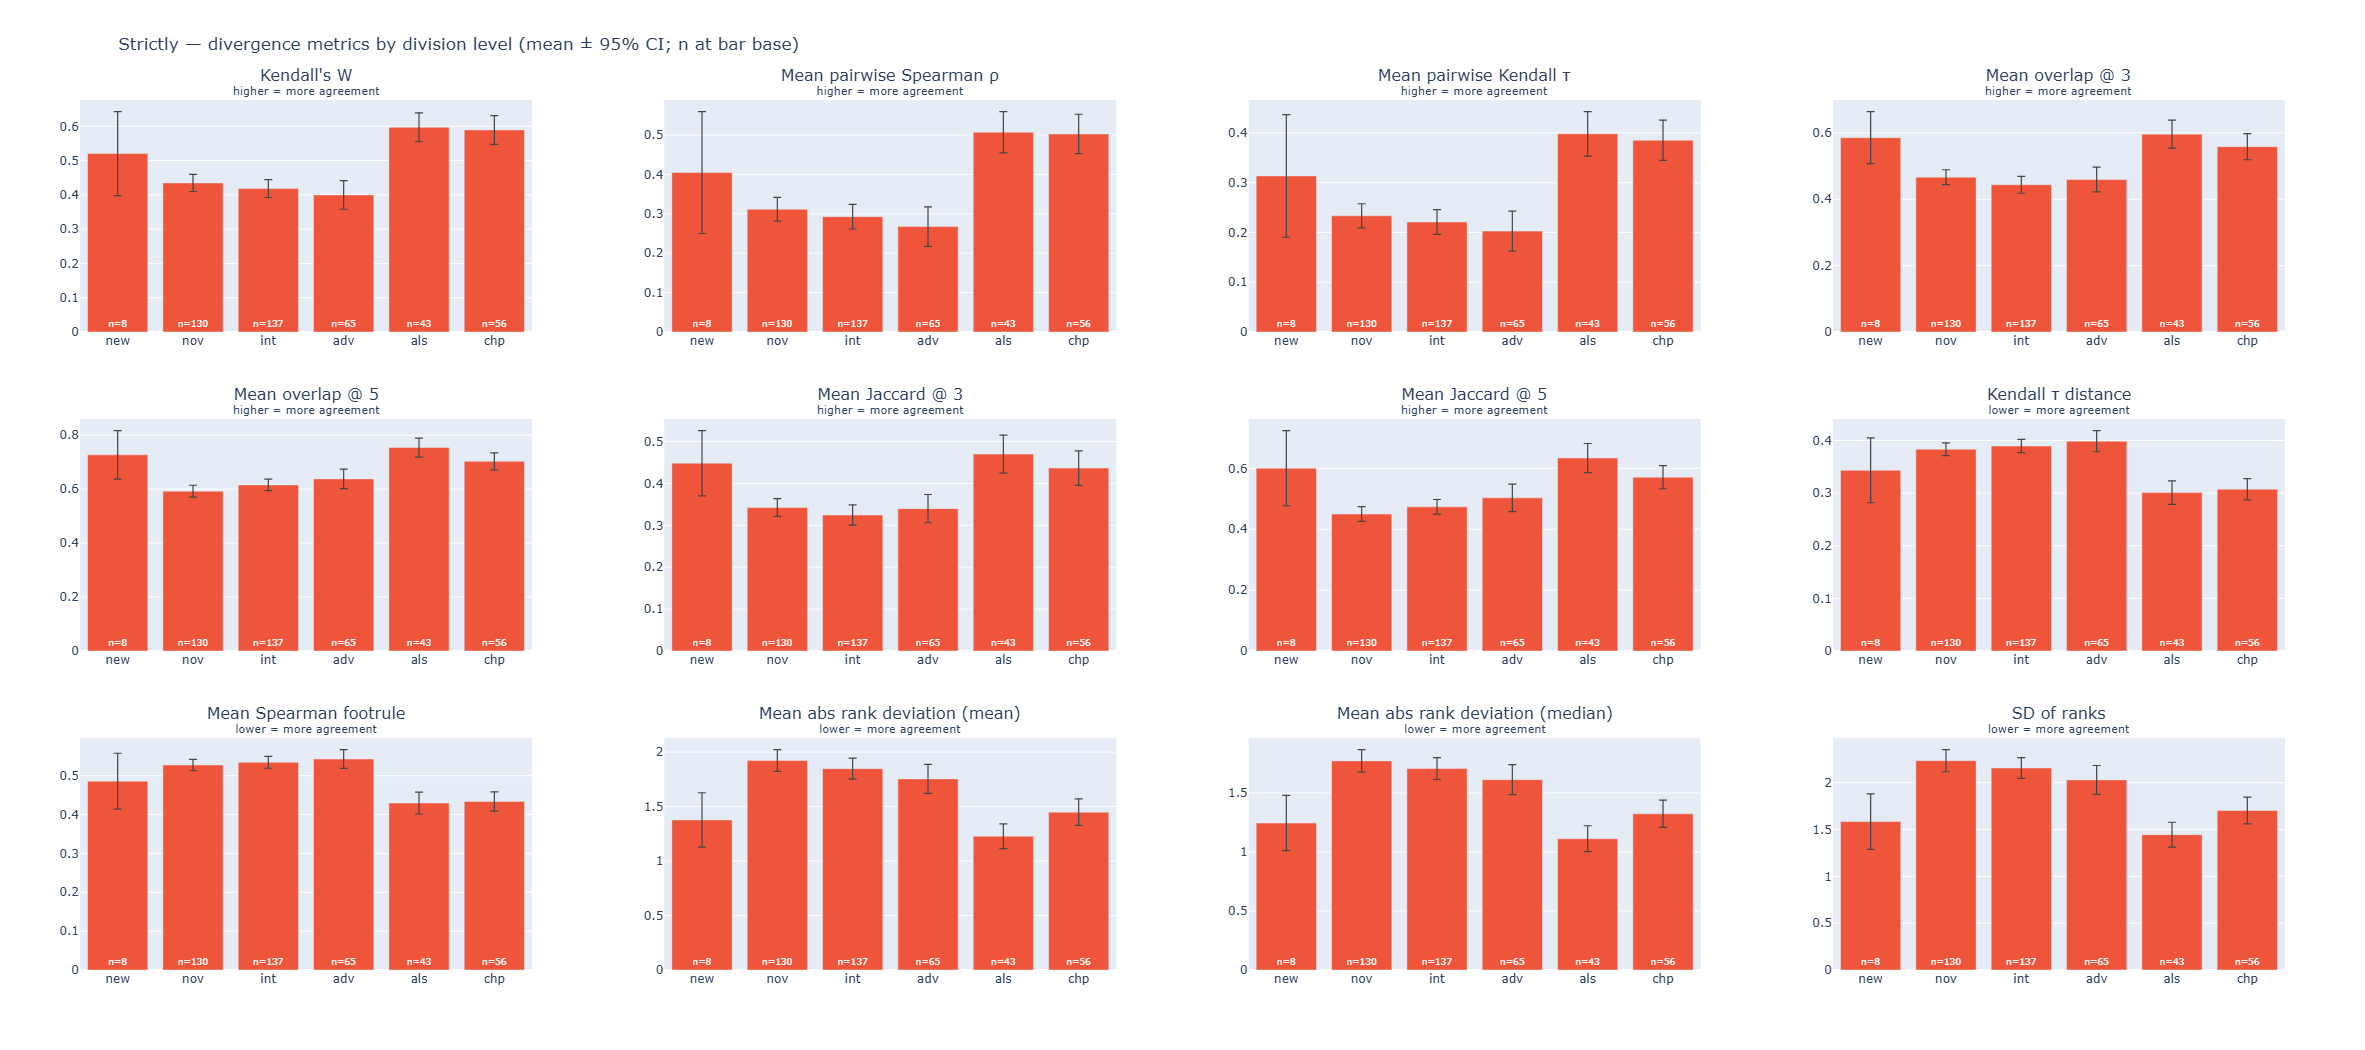

In [5]:
bar_fig("Strictly").show()

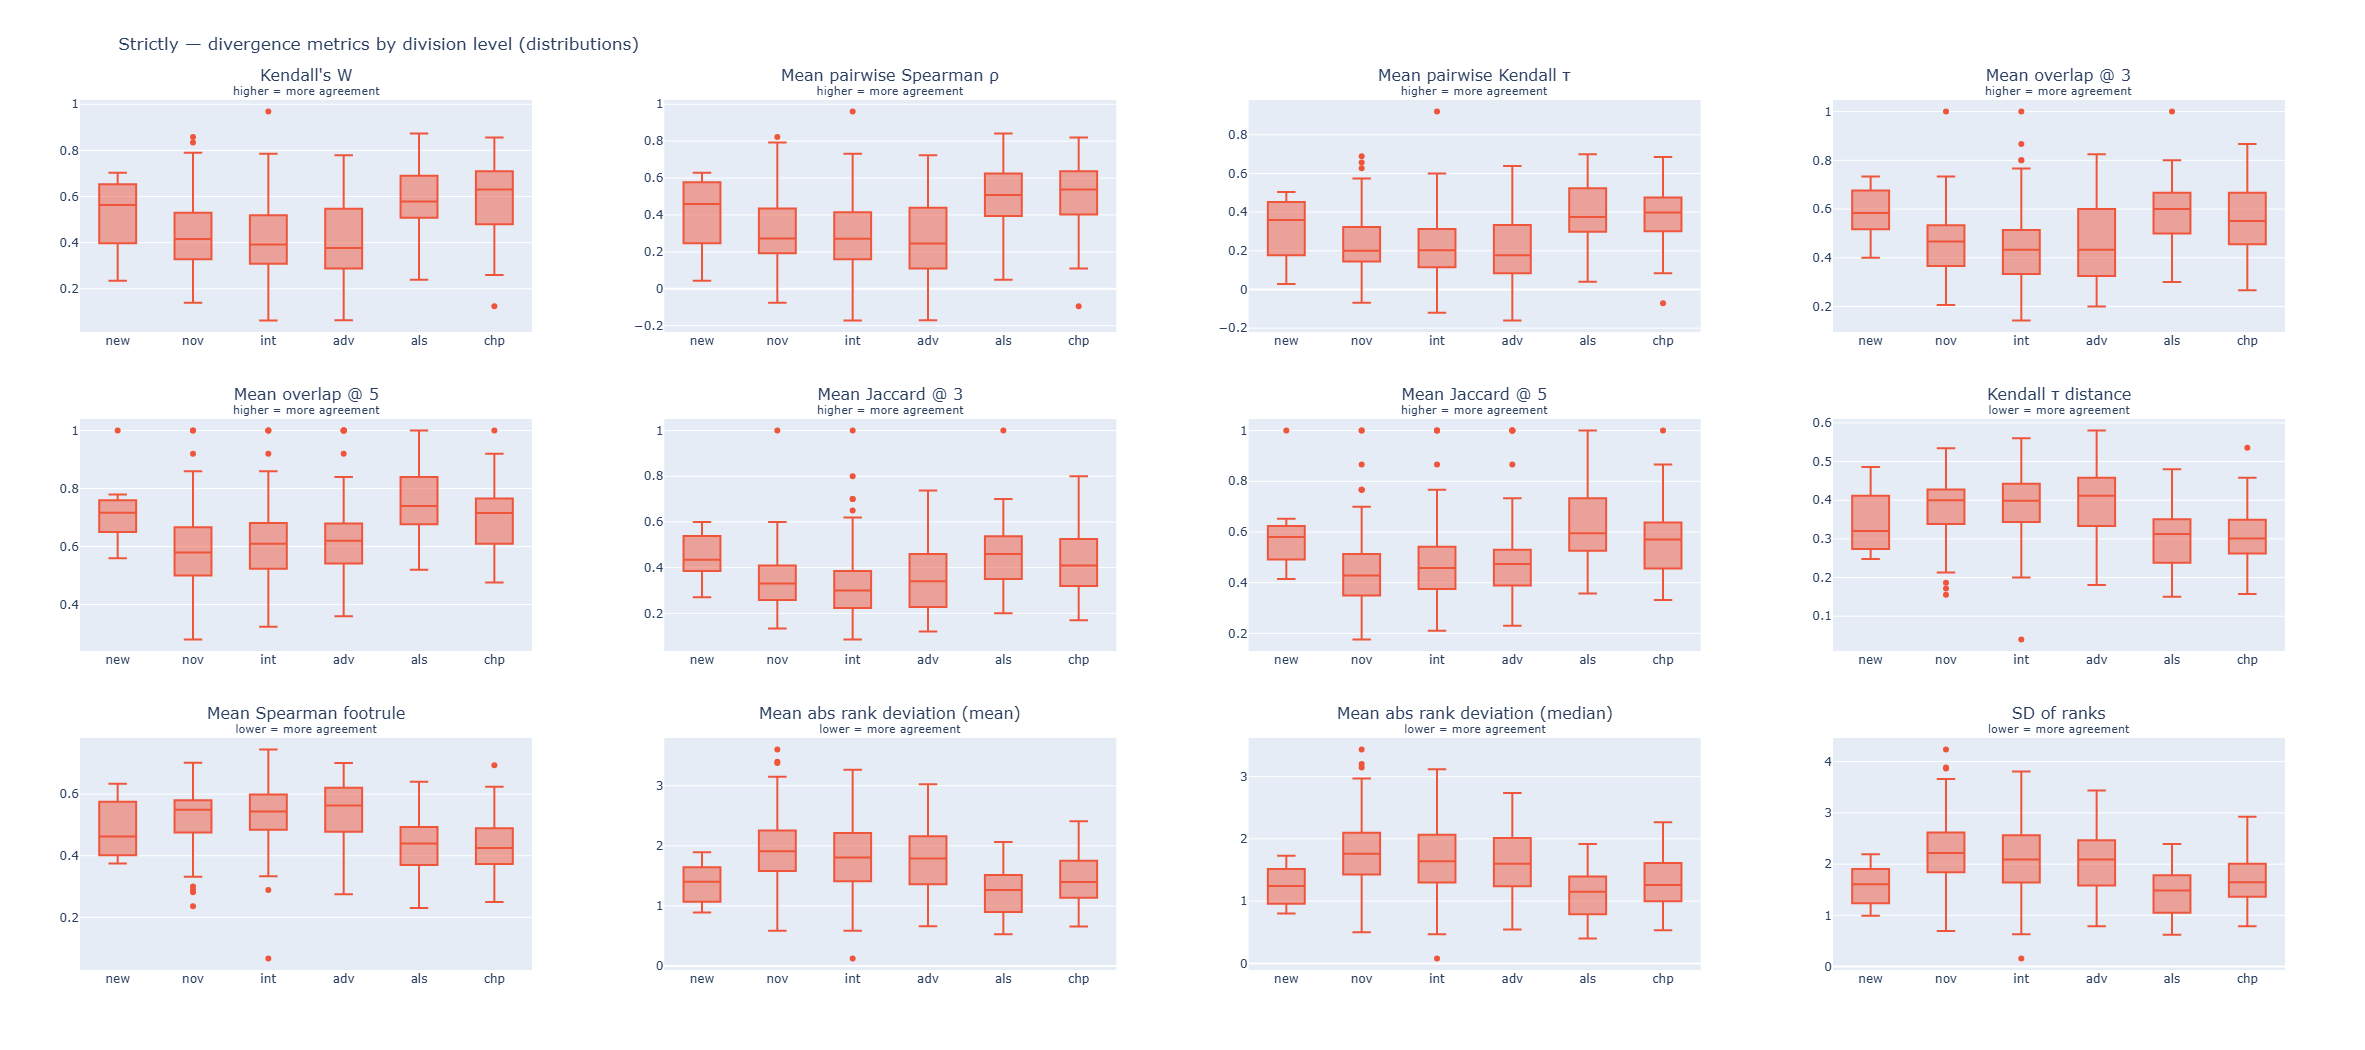

In [6]:
box_fig("Strictly").show()